# 07 - Evaluasi Metrik, Perubahan Berpasangan, dan Sensitivitas

Notebook ini menghitung metrik evaluasi utama (**Macro-F1**) dan pendamping (**Balanced Accuracy**), membandingkan perubahan berpasangan **K2 − K1** dan **K3 − K2**, menyusun *confusion matrix* gabungan, serta menampilkan uji sensitivitas ambang (`0.25` dan `1.0`) dan parameter tetap K1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, recall_score

DATA_DIR = "../data/interim/phase4-p0"
KELAS = ["SELL", "HOLD", "BUY"]
URUT_CM = ["BUY", "HOLD", "SELL"]
PERIODE = ["2023-H1", "2023-H2", "2024-H1", "2024-H2", "2025-H1", "2025-H2", "2026-Jan-Jul"]
NAMA_MODEL = {
    "regresi_logistik": "Regresi Logistik",
    "xgboost": "XGBoost",
    "mayoritas": "Kelas mayoritas",
}

pred = pd.read_parquet(f"{DATA_DIR}/06_prediksi.parquet")
kegagalan = pd.read_csv(f"{DATA_DIR}/06_kegagalan.csv")
print("Jumlah kegagalan evaluasi:", len(kegagalan))
kegagalan

Jumlah kegagalan evaluasi: 0


,ambang,periode,model,konfigurasi,alasan


## 1. Skor Macro-F1 dan Balanced Accuracy per Periode

In [2]:
def hitung_skor(g):
    benar = g["benar"].to_numpy()
    prediksi = g["prediksi"].to_numpy()
    semua_kelas_ada = all((benar == k).any() for k in KELAS)

    return pd.Series({
        "n_uji": len(g),
        "macro_f1": f1_score(benar, prediksi, labels=KELAS, average="macro", zero_division=0),
        "balanced_accuracy": recall_score(benar, prediksi, labels=KELAS, average="macro", zero_division=0) if semua_kelas_ada else np.nan,
    })

kunci = ["ambang", "analisis", "model", "konfigurasi", "periode"]
metrik = pred.groupby(kunci, sort=False)[["benar", "prediksi"]].apply(hitung_skor).reset_index()
metrik.to_csv(f"{DATA_DIR}/07_metrik_per_periode.csv", index=False)

print("Baris dengan balanced accuracy tidak terdefinisi:", int(metrik["balanced_accuracy"].isna().sum()))

utama = metrik[(metrik["ambang"] == 0.5) & (metrik["analisis"] == "disetel")]
utama.pivot_table(index="periode", columns=["model", "konfigurasi"], values="macro_f1", sort=False).reindex(PERIODE).round(4)

Baris dengan balanced accuracy tidak terdefinisi: 0


model        regresi_logistik                 xgboost                
konfigurasi                K1      K2      K3      K1      K2      K3
periode                                                              
2023-H1                0.4238  0.4232  0.4151  0.4160  0.4167  0.4201
2023-H2                0.3917  0.3927  0.3899  0.4021  0.3950  0.3897
2024-H1                0.3957  0.3979  0.3947  0.3986  0.3969  0.3961
2024-H2                0.3884  0.3888  0.3866  0.3946  0.4009  0.3993
2025-H1                0.3899  0.3872  0.3910  0.3933  0.3822  0.3914
2025-H2                0.3788  0.3787  0.3840  0.3717  0.3760  0.3778
2026-Jan-Jul           0.3767  0.3772  0.3799  0.3781  0.3793  0.3758

## 2. Rata-Rata Hasil Utama (Ambang 0,5)

In [3]:
diag = metrik[(metrik["ambang"] == 0.5) & (metrik["model"] == "mayoritas")]

tabel_utama = pd.concat([
    utama.groupby(["model", "konfigurasi"])[["macro_f1", "balanced_accuracy"]].mean(),
    diag.groupby(["model", "konfigurasi"])[["macro_f1", "balanced_accuracy"]].mean(),
]).rename(index=NAMA_MODEL, level=0)

tabel_utama.to_csv(f"{DATA_DIR}/07_rerata_utama.csv")
tabel_utama.round(6)

macro_f1  balanced_accuracy
model            konfigurasi                             
Regresi Logistik K1           0.392154           0.395686
                 K2           0.392243           0.395948
                 K3           0.391609           0.396018
XGBoost          K1           0.393499           0.397577
                 K2           0.392416           0.397104
                 K3           0.392895           0.397445
Kelas mayoritas  -            0.216652           0.333333

## 3. Perubahan Berpasangan (K2 − K1 dan K3 − K2)

In [4]:
def ambil_skor_konfig(m, konfig, analisis, nama_metrik):
    pilih = "disetel" if konfig == "K1" else analisis
    return m[(m["konfigurasi"] == konfig) & (m["analisis"] == pilih)].set_index("periode")[nama_metrik]

def ringkas_delta(metrik_df, ambang, analisis, nama_metrik):
    baris = []
    for model in ("regresi_logistik", "xgboost"):
        m = metrik_df[(metrik_df["ambang"] == ambang) & (metrik_df["model"] == model)]
        for kiri, kanan in (("K1", "K2"), ("K2", "K3")):
            selisih = (ambil_skor_konfig(m, kanan, analisis, nama_metrik) - ambil_skor_konfig(m, kiri, analisis, nama_metrik)).reindex(PERIODE).dropna()
            baris.append({
                "model": NAMA_MODEL[model],
                "perubahan": f"{kanan} − {kiri}",
                "pasangan": f"{len(selisih)}/{len(PERIODE)}",
                "rerata": selisih.mean() if len(selisih) else np.nan,
                "median": selisih.median() if len(selisih) else np.nan,
                "simpangan_baku": selisih.std(ddof=1) if len(selisih) >= 2 else np.nan,
                "periode_positif": f"{int((selisih > 0).sum())}/{len(selisih)}",
            })
    return pd.DataFrame(baris)

bagian_delta = []
for nama_metrik in ("macro_f1", "balanced_accuracy"):
    t = ringkas_delta(metrik, 0.5, "disetel", nama_metrik)
    t.insert(0, "metrik", nama_metrik)
    bagian_delta.append(t)

delta_utama = pd.concat(bagian_delta, ignore_index=True)
delta_utama.to_csv(f"{DATA_DIR}/07_delta_utama.csv", index=False)
delta_utama.round(6)

,metrik,model,perubahan,pasangan,rerata,median,simpangan_baku,periode_positif
0,macro_f1,Regresi Logistik,K2 − K1,7/7,0.000089,0.000347,0.001539,4/7
1,macro_f1,Regresi Logistik,K3 − K2,7/7,-0.000634,-0.002167,0.004770,3/7
2,macro_f1,XGBoost,K2 − K1,7/7,-0.001083,0.000707,0.006187,4/7
3,macro_f1,XGBoost,K3 − K2,7/7,0.000479,-0.000808,0.004859,3/7
4,balanced_accuracy,Regresi Logistik,K2 − K1,7/7,0.000262,0.000134,0.001714,4/7
5,balanced_accuracy,Regresi Logistik,K3 − K2,7/7,0.000070,0.000155,0.004150,4/7
6,balanced_accuracy,XGBoost,K2 − K1,7/7,-0.000473,0.000506,0.006290,4/7
7,balanced_accuracy,XGBoost,K3 − K2,7/7,0.000341,-0.000627,0.005102,3/7


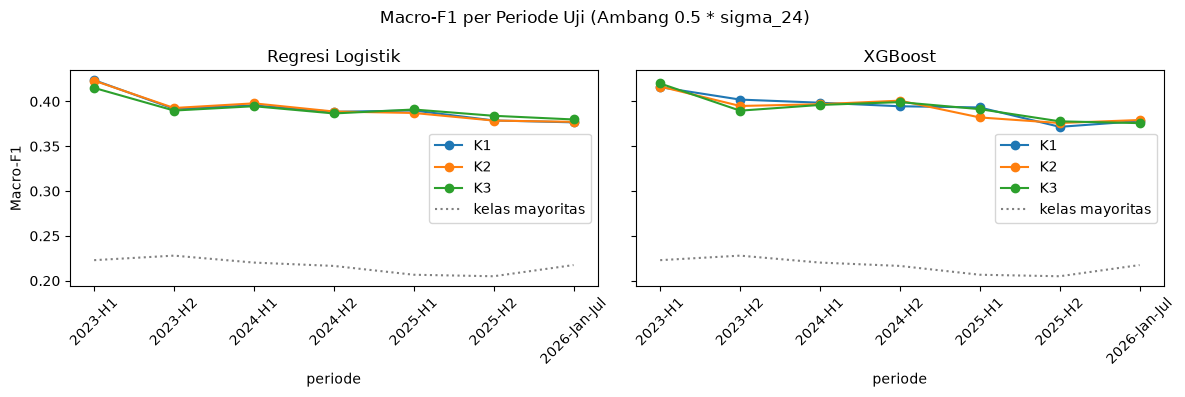

In [5]:
# Grafik Macro-F1 per periode uji
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, model in zip(axes, ("regresi_logistik", "xgboost")):
    t = utama[utama["model"] == model].pivot(index="periode", columns="konfigurasi", values="macro_f1").reindex(PERIODE)
    t.plot(ax=ax, marker="o")
    d = diag.set_index("periode")["macro_f1"].reindex(PERIODE)
    ax.plot(range(len(PERIODE)), d.to_numpy(), ls=":", color="gray", label="kelas mayoritas")
    ax.set_xticks(range(len(PERIODE)), PERIODE, rotation=45)
    ax.set_title(NAMA_MODEL[model])
    ax.legend()

axes[0].set_ylabel("Macro-F1")
fig.suptitle("Macro-F1 per Periode Uji (Ambang 0.5 * sigma_24)")
plt.tight_layout()
plt.show()

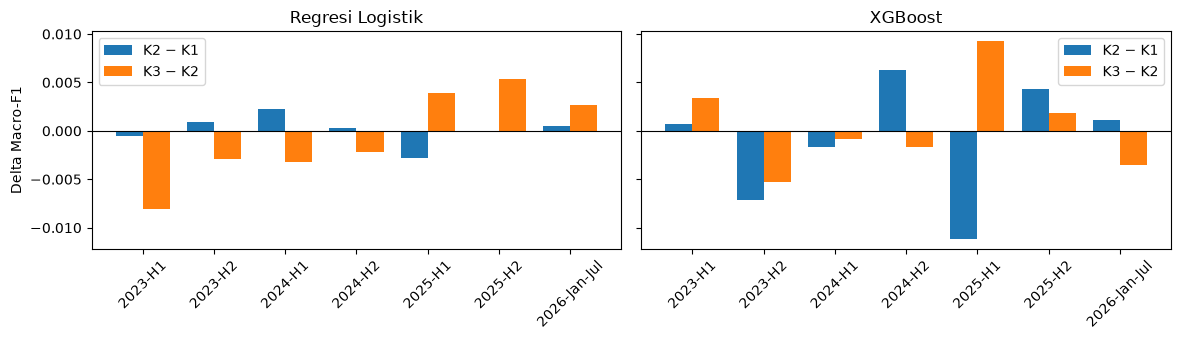

In [6]:
# Grafik selisih Macro-F1 (K2 - K1 dan K3 - K2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, model in zip(axes, ("regresi_logistik", "xgboost")):
    t = utama[utama["model"] == model].pivot(index="periode", columns="konfigurasi", values="macro_f1").reindex(PERIODE)
    lebar = 0.38
    x = np.arange(len(PERIODE))
    ax.bar(x - lebar / 2, t["K2"] - t["K1"], lebar, label="K2 − K1")
    if "K3" in t:
        ax.bar(x + lebar / 2, t["K3"] - t["K2"], lebar, label="K3 − K2")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x, PERIODE, rotation=45)
    ax.set_title(NAMA_MODEL[model])
    ax.legend()

axes[0].set_ylabel("Delta Macro-F1")
plt.tight_layout()
plt.show()

## 4. Confusion Matrix Gabungan 7 Periode Uji

Baris = label aktual, kolom = hasil prediksi (urutan: `BUY`, `HOLD`, `SELL`).

In [7]:
for model in ("regresi_logistik", "xgboost"):
    for konfig in sorted(utama["konfigurasi"].unique()):
        g = pred[
            (pred["ambang"] == 0.5)
            & (pred["analisis"] == "disetel")
            & (pred["model"] == model)
            & (pred["konfigurasi"] == konfig)
        ]
        cm = pd.DataFrame(
            confusion_matrix(g["benar"], g["prediksi"], labels=URUT_CM),
            index=URUT_CM,
            columns=URUT_CM,
        )
        print(f"{NAMA_MODEL[model]} - {konfig}")
        display(cm)

Regresi Logistik - K1


,BUY,HOLD,SELL
BUY,1444,2392,1564
HOLD,1671,5771,2150
SELL,1262,2097,1542


Regresi Logistik - K2


,BUY,HOLD,SELL
BUY,1456,2367,1577
HOLD,1691,5773,2128
SELL,1282,2088,1531


Regresi Logistik - K3


,BUY,HOLD,SELL
BUY,1463,2228,1709
HOLD,1774,5516,2302
SELL,1302,1944,1655


... (2 outputs left out)

XGBoost - K2


,BUY,HOLD,SELL
BUY,1670,1950,1780
HOLD,2109,5024,2459
SELL,1390,1762,1749


XGBoost - K3


,BUY,HOLD,SELL
BUY,1642,2003,1755
HOLD,2078,5075,2439
SELL,1377,1771,1753


## 5. Sensitivitas Ambang 0,25 dan 1,0

In [8]:
bagian_ambang = []
for a in [0.25, 1.0]:
    t = ringkas_delta(metrik, a, "disetel", "macro_f1")
    t.insert(0, "ambang", a)
    bagian_ambang.append(t)

sens_ambang = pd.concat(bagian_ambang, ignore_index=True)
sens_ambang.to_csv(f"{DATA_DIR}/07_sensitivitas_ambang.csv", index=False)
sens_ambang.round(6)

,ambang,model,perubahan,pasangan,rerata,median,simpangan_baku,periode_positif
0,0.25,Regresi Logistik,K2 − K1,7/7,0.003965,0.003791,0.002066,7/7
1,0.25,Regresi Logistik,K3 − K2,7/7,-0.001034,0.000853,0.007754,4/7
2,0.25,XGBoost,K2 − K1,7/7,-0.004523,-0.001043,0.008168,1/7
3,0.25,XGBoost,K3 − K2,7/7,-0.000310,0.000024,0.010183,4/7
4,1.00,Regresi Logistik,K2 − K1,7/7,0.001081,-0.000258,0.005905,3/7
5,1.00,Regresi Logistik,K3 − K2,7/7,-0.002286,-0.001299,0.004393,2/7
6,1.00,XGBoost,K2 − K1,7/7,0.000116,0.000033,0.007996,4/7
7,1.00,XGBoost,K3 − K2,7/7,0.009021,0.008252,0.005722,7/7


## 6. Sensitivitas Parameter Tetap (Hyperparameter K1 Dipakai Ulang)

In [9]:
bagian_tetap = []
for a in [0.5, 0.25, 1.0]:
    t = ringkas_delta(metrik, a, "parameter_tetap_k1", "macro_f1")
    t.insert(0, "ambang", a)
    bagian_tetap.append(t)

sens_tetap = pd.concat(bagian_tetap, ignore_index=True)
sens_tetap.to_csv(f"{DATA_DIR}/07_sensitivitas_parameter_tetap.csv", index=False)
sens_tetap.round(6)

,ambang,model,perubahan,pasangan,rerata,median,simpangan_baku,periode_positif
0,0.50,Regresi Logistik,K2 − K1,7/7,0.000764,0.000576,0.002407,5/7
1,0.50,Regresi Logistik,K3 − K2,7/7,-0.001368,-0.002709,0.004913,3/7
2,0.50,XGBoost,K2 − K1,7/7,-0.001877,-0.001690,0.008695,2/7
3,0.50,XGBoost,K3 − K2,7/7,0.001104,-0.000037,0.004817,3/7
4,0.25,Regresi Logistik,K2 − K1,7/7,0.004314,0.003791,0.001704,7/7
5,0.25,Regresi Logistik,K3 − K2,7/7,-0.000394,0.001736,0.007674,4/7
6,0.25,XGBoost,K2 − K1,7/7,-0.005377,-0.005187,0.007050,2/7
7,0.25,XGBoost,K3 − K2,7/7,0.001925,0.000858,0.007049,5/7
8,1.00,Regresi Logistik,K2 − K1,7/7,0.000095,-0.000908,0.005715,3/7
9,1.00,Regresi Logistik,K3 − K2,7/7,-0.000953,0.000035,0.004286,4/7
